# Étape 2 – Choix de l'entraînement

**Objectif.** L'architecture est fixée à l'étape 1 (2 couches de 128 neurones). Nous cherchons maintenant comment
l'entraîner au mieux, en comparant les choix vus en cours. Nous changeons un seul élément à la fois par rapport
à la référence Adam + initialisation He + activation ELU.

| Comparaison | Ce qui varie | Reste fixe |
|---|---|---|
| **Optimiseurs** | SGD, moment, AdaGrad, RMSProp, Adam (chacun avec son meilleur taux) | He + ELU |
| **Initialisations** | naïve, Xavier, He | Adam + ELU |
| **Activations** | ELU (référence), ReLU, tanh, sigmoïde, GELU, SiLU, linéaire (témoin) | Adam + He |

**Méthode.** Nous entraînons chaque configuration avec 3 graines et comparons la moyenne ± l'écart-type sur la
validation. La référence Adam + He + ELU est exactement le réseau retenu à l'étape 1 : nous reprenons ses
résultats tels quels.

**Simplifications.** L'étape 1 a montré qu'un entraînement complet peut prendre près d'une heure pour les plus
gros réseaux. Pour que l'ensemble des calculs reste réalisable dans le temps du projet, nous avons allégé cette
étape de trois façons, sans perdre d'information utile :
- **3 graines au lieu de 5** ;
- **le taux d'Adam n'est pas réglé à nouveau** : nous gardons celui choisi à l'étape 1 (0,001) ;
- **Leaky ReLU n'est pas testée** : sur un réseau de cette taille bien initialisé, elle se comporte comme ReLU.

Ces choix font passer l'étape 2 d'environ 90 à environ 50 entraînements.

**Sommaire**
1. Données
2. Préparation
3. Réglage du taux d'apprentissage de chaque optimiseur
4. Comparaison des initialisations et des activations
5. Meilleur taux de chaque optimiseur
6. Comparaison des optimiseurs
7. Résultats
8. Réseau final

**Configuration.** Nous chargeons les règles communes (`configs/base.yaml`) et fixons l'architecture retenue
à l'étape 1.

In [8]:
import json
import shutil

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

from heston_nn.config import load_config, repo_path
from heston_nn.data.dataset import check_dataset, load_dataset
from heston_nn.data.split import prepare_data
from heston_nn.experiments import collect_results, load_result, my_share, run_configs, summarize
from heston_nn.models.mlp import save_model
from heston_nn.plots import show_results
from heston_nn.training.optimizers import OPTIMIZERS
from heston_nn.training.train import run_experiment

cfg = load_config("configs/base.yaml")

MACHINE_ID = 0      # 0, 1, 2 ou 3 : chacun met le sien
N_MACHINES = 4

ARCHI = {"hidden_layers": 2, "width": 128}
REFERENCE = f"etape1_arch_{ARCHI['hidden_layers']}x{ARCHI['width']}"    # son nom dans results/
CONFIGS = repo_path("configs", "etape2")
SEEDS = [0, 1, 2]                                    # 3 graines, comme dans les TP (étape 1 : 5)
print("architecture :", ARCHI, "| référence :", REFERENCE)

architecture : {'hidden_layers': 2, 'width': 128} | référence : etape1_arch_2x128


## 1. Données
Nous reprenons les données du notebook 01, avec le même découpage 80 / 10 / 10 (graine 42) et la même
normalisation.

In [9]:
X, Y = load_dataset(repo_path("data", "surfaces.npz"))
print(check_dataset(X, Y, cfg))

prepared = prepare_data(X, Y, cfg)        # (données normalisées, x_scaler, y_scaler)
scaled, x_scaler, y_scaler = prepared
for part in ["train", "val", "test"]:
    print(part, scaled[part][0].shape)

{'n_surfaces': 50000, 'n_surfaces_with_nan': 28078, 'n_nan_points': 83827, 'share_nan_points': 0.01905159090909091}
train (40000, 5)
val (5000, 5)
test (5000, 5)


## 2. Préparation
Nous écrivons l'architecture retenue dans les configurations de cette étape. Les résultats de la référence
(Adam + He + ELU) sont repris de l'étape 1, puisqu'il s'agit exactement du même réseau, entraîné de la même façon
avec les mêmes graines.

In [10]:
for path in sorted(CONFIGS.glob("serie*.yaml")):
    text = path.read_text(encoding="utf-8")
    text = text.replace("ARCHI_PROFONDEUR", str(ARCHI["hidden_layers"]))
    text = text.replace("ARCHI_LARGEUR", str(ARCHI["width"]))
    path.write_text(text, encoding="utf-8")
print("architecture écrite dans les configs :", ARCHI)


def reuse_reference(new_name):
    """Recopie les graines de la référence de l'étape 1 sous un nouveau nom (même réseau, même entraînement)."""
    seed_dirs = [repo_path("results", REFERENCE, f"seed_{seed}") for seed in SEEDS]
    assert all((d / "metrics.json").exists() for d in seed_dirs), f"résultats de {REFERENCE} incomplets : faire git pull"
    for seed_dir in seed_dirs:
        target = repo_path("results", new_name, seed_dir.name)
        target.mkdir(parents=True, exist_ok=True)
        metrics = json.loads((seed_dir / "metrics.json").read_text(encoding="utf-8"))
        metrics["name"] = new_name
        (target / "metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
        shutil.copy(seed_dir / "history.csv", target / "history.csv")
    print(f"{REFERENCE} -> {new_name}")


reuse_reference("etape2_serieB_he")     # He = la référence de la série B
reuse_reference("etape2_serieC_elu")    # ELU = la référence de la série C

architecture écrite dans les configs : {'hidden_layers': 2, 'width': 128}
etape1_arch_2x128 -> etape2_serieB_he
etape1_arch_2x128 -> etape2_serieC_elu


## 3. Réglage du taux d'apprentissage de chaque optimiseur
Chaque optimiseur a son propre bon taux d'apprentissage : un taux adapté à Adam est souvent trop petit pour SGD.
Pour comparer des optimiseurs bien réglés, nous entraînons chacun avec trois taux (1e-2, 1e-3 et 1e-4) sur une
graine. Adam garde le taux choisi à l'étape 1.

In [11]:
TUNED = [optimizer for optimizer in OPTIMIZERS if optimizer != "adam"]   # Adam : taux déjà réglé à l'étape 1
tuning_jobs = [(optimizer, lr) for optimizer in TUNED for lr in [1e-2, 1e-3, 1e-4]]

for optimizer, learning_rate in my_share(tuning_jobs, MACHINE_ID, N_MACHINES):
    run_cfg = load_config(CONFIGS / f"serieA_{optimizer}.yaml")
    run_cfg["train"]["lr"] = learning_rate                        # seul le taux change
    run_cfg["name"] = f"reglageA_{optimizer}_{learning_rate}"
    if repo_path("results", run_cfg["name"], "seed_0", "metrics.json").exists():
        print(f"{run_cfg['name']} : déjà fait")
    else:
        run_experiment(run_cfg, seed=0, prepared=prepared)       # une graine suffit pour régler

reglageA_sgd_0.01 : déjà fait
reglageA_momentum_0.001 : déjà fait
reglageA_adagrad_0.0001 : déjà fait


## 4. Comparaison des initialisations et des activations
Nous entraînons les initialisations (naïve, Xavier) et les activations (ReLU, tanh, sigmoïde, GELU, SiLU,
linéaire) avec les 3 graines. Les autres réglages restent ceux de la référence.

In [12]:
jobs_BC = [(path, seed)
           for path in sorted(CONFIGS.glob("serie[BC]_*.yaml"))
           if path.stem not in ("serieB_he", "serieC_elu")          # déjà là grâce à la référence
           for seed in SEEDS]
results_BC = run_configs(my_share(jobs_BC, MACHINE_ID, N_MACHINES), prepared)

Entraînements:   0%|          | 0/6 [00:00<?, ?run/s]

etape2_serieB_naive – graine 0 : déjà fait, on relit le résultat
etape2_serieB_xavier – graine 1 : déjà fait, on relit le résultat
etape2_serieC_gelu – graine 2 : déjà fait, on relit le résultat
etape2_serieC_relu – graine 0 : déjà fait, on relit le résultat
etape2_serieC_sigmoid – graine 1 : déjà fait, on relit le résultat
etape2_serieC_silu – graine 2 : déjà fait, on relit le résultat


## 5. Meilleur taux de chaque optimiseur
Le tableau donne l'erreur moyenne de validation (en pb) pour chaque optimiseur et chaque taux. Nous retenons le
meilleur taux de chacun pour la comparaison des optimiseurs.

In [13]:
rows = [load_result(d)["metrics"] for d in sorted(repo_path("results").glob("reglageA_*/seed_0"))]
print(len(rows), "réglages trouvés sur", len(TUNED) * 3)
tuning = pd.DataFrame(rows)
tuning["optimizer"] = tuning["name"].str.split("_").str[1]
tuning["lr"] = tuning["name"].str.split("_").str[2].astype(float)
best_lr = tuning.loc[tuning.groupby("optimizer")["val_mean_bp"].idxmin(), ["optimizer", "lr", "val_mean_bp"]]

for _, row in best_lr.iterrows():                                  # écrit le meilleur taux dans chaque config
    path = CONFIGS / f"serieA_{row['optimizer']}.yaml"
    path.write_text(path.read_text(encoding="utf-8").replace("lr: A_REGLER", f"lr: {row['lr']}"),
                    encoding="utf-8")
adam_path = CONFIGS / "serieA_adam.yaml"                           # Adam : le taux de l'étape 1
adam_path.write_text(adam_path.read_text(encoding="utf-8").replace("lr: A_REGLER", f"lr: {cfg['train']['lr']}"),
                     encoding="utf-8")
print(best_lr.to_string(index=False))

tuning.pivot(index="optimizer", columns="lr", values="val_mean_bp").round(1)   # tableau optimiseur × taux

12 réglages trouvés sur 12
optimizer    lr  val_mean_bp
  adagrad 0.010    21.255507
 momentum 0.010    11.429911
  rmsprop 0.001     5.595010
      sgd 0.010    32.062911


lr,0.0001,0.0010,0.0100
optimizer,,,
adagrad,155.3,58.7,21.3
momentum,70.0,32.0,11.4
rmsprop,9.7,5.6,28.3
sgd,139.0,70.0,32.1


Le taux compte autant que l'optimiseur : RMSProp passe de 28,3 à 5,6 pb selon le taux. Pour SGD, le moment et
AdaGrad, le meilleur taux est le plus grand que nous avons testé (0,01) : un taux plus grand pourrait encore les
améliorer.

## 6. Comparaison des optimiseurs
Nous entraînons les 5 optimiseurs, chacun avec son meilleur taux, sur les 3 graines. Pour Adam, les résultats
sont ceux de la référence.

In [6]:
if load_config(CONFIGS / "serieA_adam.yaml")["train"]["lr"] == cfg["train"]["lr"]:
    reuse_reference("etape2_serieA_adam")     # même taux qu'à l'étape 1 : c'est encore la référence

jobs_A = [(CONFIGS / f"serieA_{optimizer}.yaml", seed) for optimizer in OPTIMIZERS for seed in SEEDS]
results_A = run_configs(my_share(jobs_A, MACHINE_ID, N_MACHINES), prepared)

etape1_arch_2x128 -> etape2_serieA_adam


Entraînements:   0%|          | 0/4 [00:00<?, ?run/s]

etape2_serieA_sgd – graine 0 : déjà fait, on relit le résultat
etape2_serieA_momentum – graine 1 : déjà fait, on relit le résultat
etape2_serieA_adagrad – graine 2 : déjà fait, on relit le résultat
etape2_serieA_adam – graine 0 : déjà fait, on relit le résultat


## 7. Résultats
Pour chaque comparaison, nous traçons les courbes d'apprentissage (moyenne ± écart-type sur les 3 graines,
entraînement en trait plein, validation en pointillés) et donnons le tableau des erreurs.

45 entraînements trouvés


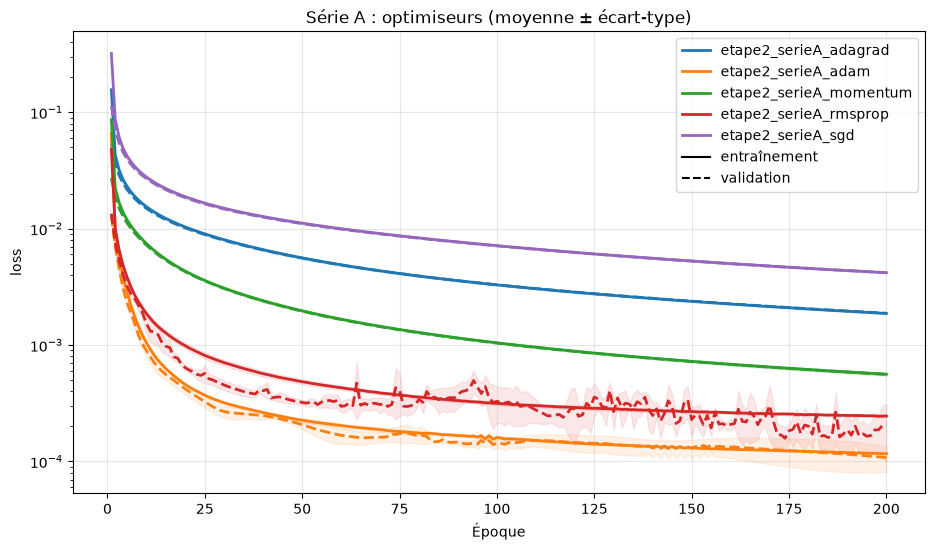

,n_seeds,val_mean_bp,val_mean_bp_std,test_mean_bp,test_mean_bp_std,test_max_bp,n_params,training_time_s
name,,,,,,,,
etape2_serieA_adam,3,5.11,0.71,5.10,0.67,152.65,28632,122.84
etape2_serieA_rmsprop,3,5.93,1.06,5.93,1.02,177.06,28632,112.32
etape2_serieA_momentum,3,11.41,0.16,11.46,0.19,278.25,28632,103.62
etape2_serieA_adagrad,3,21.25,0.16,21.35,0.16,412.41,28632,117.13
etape2_serieA_sgd,3,32.26,0.17,32.39,0.21,591.77,28632,99.67


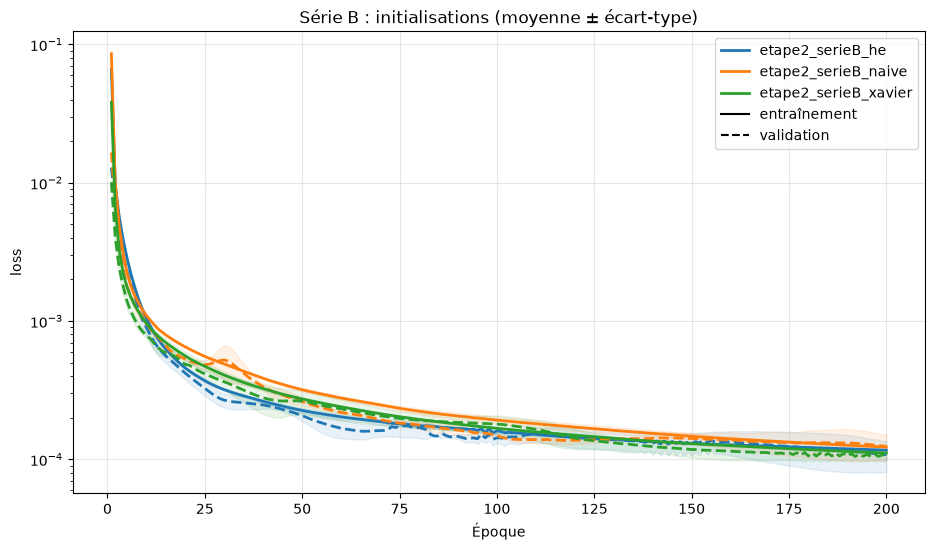

,n_seeds,val_mean_bp,val_mean_bp_std,test_mean_bp,test_mean_bp_std,test_max_bp,n_params,training_time_s
name,,,,,,,,
etape2_serieB_xavier,3,5.04,0.39,5.03,0.35,171.36,28632,96.13
etape2_serieB_he,3,5.11,0.71,5.10,0.67,152.65,28632,122.84
etape2_serieB_naive,3,5.31,0.24,5.31,0.28,170.85,28632,104.47


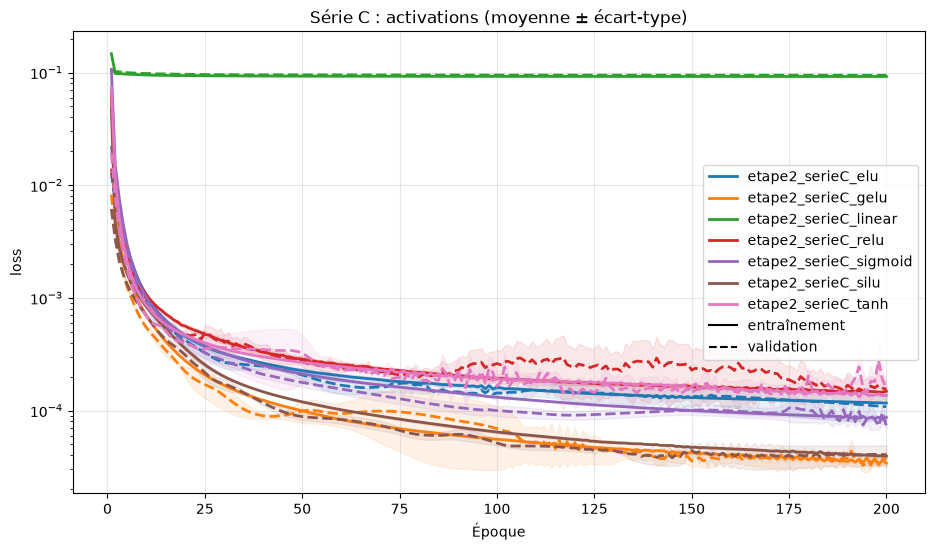

,n_seeds,val_mean_bp,val_mean_bp_std,test_mean_bp,test_mean_bp_std,test_max_bp,n_params,training_time_s
name,,,,,,,,
etape2_serieC_gelu,3,2.66,0.09,2.67,0.08,97.76,28632,143.30
etape2_serieC_silu,3,2.75,0.20,2.73,0.17,116.27,28632,145.71
etape2_serieC_sigmoid,3,4.24,0.20,4.25,0.19,169.63,28632,97.36
etape2_serieC_tanh,3,5.05,0.60,5.05,0.57,146.53,28632,97.35
etape2_serieC_elu,3,5.11,0.71,5.10,0.67,152.65,28632,122.84
etape2_serieC_relu,3,6.16,0.99,6.19,0.97,126.19,28632,93.94
etape2_serieC_linear,3,155.66,1.20,154.73,0.76,1704.28,28632,94.94


In [25]:
results = collect_results(2)
print(len(results), "entraînements trouvés")

for serie, title in [("A", "optimiseurs"), ("B", "initialisations"), ("C", "activations")]:
    subset = [r for r in results if r["type"].startswith(f"etape2_serie{serie}_")]
    show_results(subset, metric_name="loss", title=f"Série {serie} : {title} (moyenne ± écart-type)",
                 save_path=repo_path("results", "figures", f"etape2_serie{serie}.png"))
    plt.show()
    display(summarize(subset).round(2))

- **Optimiseurs :** les méthodes adaptatives dominent. Adam (5,1 pb) et RMSProp (5,9 pb) sont loin devant le
  moment (11,4 pb), AdaGrad (21,3 pb) et SGD (32,3 pb).
- **Initialisations :** l'initialisation compte peu pour ce réseau de 2 couches (Xavier 5,0 pb, He 5,1 pb,
  naïve 5,3 pb).
- **Activations :** c'est le choix qui compte le plus. GELU (2,66 pb) et SiLU (2,75 pb), deux activations lisses,
  divisent l'erreur par deux par rapport à ELU (5,11 pb) et font bien mieux que ReLU (6,16 pb). Le témoin
  linéaire échoue (156 pb) : sans non-linéarité, le réseau n'est qu'une régression linéaire.

## 8. Réseau final
Nous combinons d'abord le meilleur réglage de chaque comparaison (sur la validation) : Adam, initialisation
Xavier, activation GELU. Ces choix ayant été testés un par un, nous vérifions qu'ensemble ils font mieux que la
référence.

In [26]:
def best_of(serie):
    """Le meilleur réglage d'une série, sur la VALIDATION (ex. 'rmsprop', 'he', 'gelu')."""
    subset = [r for r in results if r["type"].startswith(f"etape2_serie{serie}_")]
    return summarize(subset).index[0].removeprefix(f"etape2_serie{serie}_")


best_optimizer, best_init, best_activation = best_of("A"), best_of("B"), best_of("C")
best_optimizer_lr = load_config(CONFIGS / f"serieA_{best_optimizer}.yaml")["train"]["lr"]

final = {"name": "etape2_final",
         "model": {**ARCHI, "init": best_init, "activation": best_activation},
         "train": {"optimizer": best_optimizer, "lr": best_optimizer_lr}}
(CONFIGS / "final.yaml").write_text(yaml.safe_dump(final, sort_keys=False), encoding="utf-8")
print("réseau final :", final)

final_results = run_configs([(CONFIGS / "final.yaml", seed) for seed in SEEDS], prepared)

réseau final : {'name': 'etape2_final', 'model': {'hidden_layers': 2, 'width': 128, 'init': 'xavier', 'activation': 'gelu'}, 'train': {'optimizer': 'adam', 'lr': 0.001}}


Entraînements:   0%|          | 0/3 [00:00<?, ?run/s]

etape2_final – graine 0 : entraînement…


etape2_final – graine 0:   0%|          | 0/200 [00:00<?, ?époque/s]

etape2_final – graine 1 : entraînement…


etape2_final – graine 1:   0%|          | 0/200 [00:00<?, ?époque/s]

etape2_final – graine 2 : entraînement…


etape2_final – graine 2:   0%|          | 0/200 [00:00<?, ?époque/s]

In [27]:
reference = [r for r in results if r["type"] == "etape2_serieC_elu"]       # la référence Adam + He + ELU
display(summarize(final_results + reference).round(2))                     # le réseau combiné fait-il mieux ?

best_run = min(final_results, key=lambda r: r["metrics"]["val_mean_bp"])   # meilleure graine, sur la validation
model = keras.models.load_model(repo_path("results", "etape2_final", f"seed_{best_run['seed']}", "model.keras"),
                                compile=False)
save_model(repo_path("results", "reseau_final"), model, x_scaler, y_scaler, load_config(CONFIGS / "final.yaml"))
print(f"réseau final enregistré (graine {best_run['seed']}) : "
      f"{best_run['metrics']['test_mean_bp']:.2f} pb en moyenne sur le test")

,n_seeds,val_mean_bp,val_mean_bp_std,test_mean_bp,test_mean_bp_std,test_max_bp,n_params,training_time_s
name,,,,,,,,
etape2_final,3,2.91,0.14,2.92,0.13,105.33,28632,140.11
etape2_serieC_elu,3,5.11,0.71,5.10,0.67,152.65,28632,122.84


réseau final enregistré (graine 1) : 2.77 pb en moyenne sur le test


La combinaison Adam + Xavier + GELU (2,91 ± 0,14 pb) fait moins bien que GELU avec l'initialisation He
(2,66 ± 0,09 pb) : les meilleurs choix ne s'additionnent pas. Xavier est un peu meilleure avec ELU, mais moins
bonne avec GELU. Le réseau final est donc **Adam + He + GELU**. Nous le réentraînons sur ses 3 graines et
enregistrons la meilleure (sur la validation) dans `results/reseau_final/`.

In [28]:
# La combinaison (Xavier + GELU) fait moins bien que GELU avec He : le réseau final est Adam + He + GELU.
final = {"name": "etape2_final_he",
         "model": {**ARCHI, "init": "he", "activation": "gelu"},
         "train": {"optimizer": "adam", "lr": cfg["train"]["lr"]}}
(CONFIGS / "final_he.yaml").write_text(yaml.safe_dump(final, sort_keys=False), encoding="utf-8")
final_he = run_configs([(CONFIGS / "final_he.yaml", seed) for seed in SEEDS], prepared)
display(summarize(final_he + final_results + reference).round(2))

best_run = min(final_he, key=lambda r: r["metrics"]["val_mean_bp"])
model = keras.models.load_model(repo_path("results", "etape2_final_he", f"seed_{best_run['seed']}", "model.keras"),
                                compile=False)
save_model(repo_path("results", "reseau_final"), model, x_scaler, y_scaler, load_config(CONFIGS / "final_he.yaml"))
print(f"réseau final : Adam + He + GELU (graine {best_run['seed']}) : "
      f"{best_run['metrics']['test_mean_bp']:.2f} pb en moyenne sur le test")

Entraînements:   0%|          | 0/3 [00:00<?, ?run/s]

etape2_final_he – graine 0 : entraînement…


etape2_final_he – graine 0:   0%|          | 0/200 [00:00<?, ?époque/s]

etape2_final_he – graine 1 : entraînement…


etape2_final_he – graine 1:   0%|          | 0/200 [00:00<?, ?époque/s]

etape2_final_he – graine 2 : entraînement…


etape2_final_he – graine 2:   0%|          | 0/200 [00:00<?, ?époque/s]

,n_seeds,val_mean_bp,val_mean_bp_std,test_mean_bp,test_mean_bp_std,test_max_bp,n_params,training_time_s
name,,,,,,,,
etape2_final_he,3,2.66,0.09,2.67,0.08,97.76,28632,135.92
etape2_final,3,2.91,0.14,2.92,0.13,105.33,28632,140.11
etape2_serieC_elu,3,5.11,0.71,5.10,0.67,152.65,28632,122.84


réseau final : Adam + He + GELU (graine 0) : 2.58 pb en moyenne sur le test


## Conclusion
**Réseau final : 2 × 128, Adam (taux 0,001), initialisation He, activation GELU** : 2,66 ± 0,09 pb sur la
validation, **2,58 pb sur le test** pour la graine retenue, contre 5,1 pb pour la référence Adam + He + ELU.

- **L'activation est le choix qui compte le plus.** Les activations lisses GELU et SiLU divisent l'erreur par
  deux par rapport à ELU. Une surface de volatilité varie de façon lisse avec les paramètres : une activation
  lisse l'approche mieux, et donne un réseau régulier, utile pour la calibration. Le témoin linéaire échoue :
  sans non-linéarité, le réseau ne peut pas représenter la surface.
- **L'optimiseur compte beaucoup.** Les méthodes adaptatives (Adam, RMSProp) dominent nettement, et le réglage
  du taux est essentiel pour chacun.
- **L'initialisation compte peu** pour un réseau de 2 couches.
- **Les meilleurs choix ne s'additionnent pas toujours.** La combinaison Adam + Xavier + GELU fait moins bien
  que GELU avec He : il faut vérifier une combinaison avant de la retenir.
- La validation et le test donnent les mêmes erreurs : il n'y a pas de surapprentissage.